In [1]:
# === Define base path ===
BASE_DIR="/content/drive/MyDrive/uni_datasets/VQAv2"

# === Create directories ===
!mkdir -p "$BASE_DIR/images"
!mkdir -p "$BASE_DIR/annotations"
!mkdir -p "$BASE_DIR/questions"

# === Images ===
!wget -c http://images.cocodataset.org/zips/train2014.zip -P "$BASE_DIR/images"
!unzip -q "$BASE_DIR/images/train2014.zip" -d "$BASE_DIR/images"
!rm "$BASE_DIR/images/train2014.zip"

!wget -c http://images.cocodataset.org/zips/val2014.zip -P "$BASE_DIR/images"
!unzip -q "$BASE_DIR/images/val2014.zip" -d "$BASE_DIR/images"
!rm "$BASE_DIR/images/val2014.zip"

!wget -c http://images.cocodataset.org/zips/test2015.zip -P "$BASE_DIR/images"
!unzip -q "$BASE_DIR/images/test2015.zip" -d "$BASE_DIR/images"
!rm "$BASE_DIR/images/test2015.zip"

# === Annotations ===
!wget -c https://cvmlp.s3.amazonaws.com/vqa/mscoco/vqa/v2_Annotations_Train_mscoco.zip -P "$BASE_DIR/annotations"
!unzip -q "$BASE_DIR/annotations/v2_Annotations_Train_mscoco.zip" -d "$BASE_DIR/annotations"
!rm "$BASE_DIR/annotations/v2_Annotations_Train_mscoco.zip"

!wget -c https://cvmlp.s3.amazonaws.com/vqa/mscoco/vqa/v2_Annotations_Val_mscoco.zip -P "$BASE_DIR/annotations"
!unzip -q "$BASE_DIR/annotations/v2_Annotations_Val_mscoco.zip" -d "$BASE_DIR/annotations"
!rm "$BASE_DIR/annotations/v2_Annotations_Val_mscoco.zip"

# === Questions ===
!wget -c https://cvmlp.s3.amazonaws.com/vqa/mscoco/vqa/v2_Questions_Train_mscoco.zip -P "$BASE_DIR/questions"
!unzip -q "$BASE_DIR/questions/v2_Questions_Train_mscoco.zip" -d "$BASE_DIR/questions"
!rm "$BASE_DIR/questions/v2_Questions_Train_mscoco.zip"

!wget -c https://cvmlp.s3.amazonaws.com/vqa/mscoco/vqa/v2_Questions_Val_mscoco.zip -P "$BASE_DIR/questions"
!unzip -q "$BASE_DIR/questions/v2_Questions_Val_mscoco.zip" -d "$BASE_DIR/questions"
!rm "$BASE_DIR/questions/v2_Questions_Val_mscoco.zip"

!wget -c https://cvmlp.s3.amazonaws.com/vqa/mscoco/vqa/v2_Questions_Test_mscoco.zip -P "$BASE_DIR/questions"
!unzip -q "$BASE_DIR/questions/v2_Questions_Test_mscoco.zip" -d "$BASE_DIR/questions"
!rm "$BASE_DIR/questions/v2_Questions_Test_mscoco.zip"


--2025-10-26 06:26:49--  http://images.cocodataset.org/zips/train2014.zip
Resolving images.cocodataset.org (images.cocodataset.org)... 16.15.201.185, 16.182.73.137, 16.182.102.57, ...
Connecting to images.cocodataset.org (images.cocodataset.org)|16.15.201.185|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 13510573713 (13G) [application/zip]
Saving to: ‘/content/drive/MyDrive/uni_datasets/VQAv2/images/train2014.zip’

train2014.zip       100%[===================>]  12.58G  54.7MB/s    in 3m 54s  

2025-10-26 06:30:43 (55.2 MB/s) - ‘/content/drive/MyDrive/uni_datasets/VQAv2/images/train2014.zip’ saved [13510573713/13510573713]

--2025-10-26 06:32:27--  http://images.cocodataset.org/zips/val2014.zip
Resolving images.cocodataset.org (images.cocodataset.org)... 52.216.250.12, 16.182.97.241, 52.217.226.9, ...
Connecting to images.cocodataset.org (images.cocodataset.org)|52.216.250.12|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 6645013297 

In [2]:
# 🧹 Step 1: Clear cache and upgrade libraries
!rm -rf ~/.cache/huggingface
!rm -rf /root/.cache/huggingface
!pip install --upgrade transformers huggingface_hub git-lfs

# 🪝 Step 2: Clone the correct model repo locally
!git lfs install
!git clone https://huggingface.co/bert-base-uncased

# 🧠 Step 3: Load tokenizer from the local folder
from transformers import BertTokenizer

tokenizer = BertTokenizer.from_pretrained("./bert-base-uncased")
print("✅ Tokenizer loaded successfully!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 89.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.1/566.1 kB 40.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 89.5 MB/s eta 0:00:00
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface-hub 1.0.0rc2
    Uninstalling huggingface-hub-1.0.0rc2:
      Successfully uninstalled huggingface-hub-1.0.0rc2
  Attempting uninstall: tokenizers
    Found existing installation: tokenizers 0.21.2
    Uninstalling tokenizers-0.21.2:
      Successfully uninstalled tokenizers-0.21.2
  Attempting uninstall: transformers
    Found existing installation: transformers 4.53.3
    Uninstalling transformers-4.53.3:
      Successfully uninstalled transformers-4.53.3
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source 

In [3]:
import random
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms, utils as vutils
import matplotlib.pyplot as plt
import numpy as np
from torch.utils.data import Subset
from transformers import BertTokenizer, BertModel
from PIL import Image
from tqdm import tqdm
import os
from torchvision.models import resnet50
from transformers import BertTokenizer

tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
from torchvision import models
from collections import Counter
import json

SEED = 69
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)


REDUCED_TRAINING = False


def build_answer_vocab(annotations_path, top_k=1000):
  with open(annotations_path, 'r') as f:
     annotations = json.load(f)['annotations']
     answers = [ann['multiple_choice_answer'] for ann in annotations]
     counter = Counter(answers)
     most_common = counter.most_common(top_k)
     answer_to_id = {"<unk>": 0}
     id_to_answer = {0: "<unk>"}
     for idx, (ans, _) in enumerate(most_common, start=1):
        answer_to_id[ans] = idx
        id_to_answer[idx] = ans
  return answer_to_id, id_to_answer


2025-10-26 06:43:21.350612: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1761461001.527152      19 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1761461001.580282      19 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [4]:


class VQAv2Dataset(Dataset):
    def __init__(self, image_dir, questions_path, annotations_path,
                 tokenizer, device, answer_to_id=None,
                 transform=None, max_length=32, cache_features=True):

        self.image_dir = image_dir
        self.tokenizer = tokenizer
        self.max_length = max_length
        self.answer_to_id = answer_to_id
        self.device = device
        self.cache_features = cache_features

        # Load questions and annotations
        with open(questions_path, 'r') as f:
            self.questions = json.load(f)['questions']
        if annotations_path is not None:
            with open(annotations_path, 'r') as f:
                self.annotations = json.load(f)['annotations']
        else:
            self.annotations = None

        # Transform for raw image
        if transform is None:
            self.transform = transforms.Compose([
                transforms.Resize((224, 224)),
                transforms.ToTensor(),
                transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                     std=[0.229, 0.224, 0.225]) # apparently this is better cuz resnet weights are pretrained on imageNet
            ])
        else:
            self.transform = transform

        # Build feature extractor (no FC layer)
        if self.cache_features:
            self.feature_extractor = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
            self.feature_extractor = torch.nn.Sequential(*list(self.feature_extractor.children())[:-1])
            self.feature_extractor.eval().to(self.device)

        # Cache dict: image_id -> tensor(2048)
        self.feature_cache = {}

    def __len__(self):
        return len(self.questions)

    def _get_image_path(self, image_id):
        path = os.path.join(self.image_dir, f"COCO_train2014_{image_id:012d}.jpg")
        if not os.path.exists(path):
            path = os.path.join(self.image_dir, f"COCO_val2014_{image_id:012d}.jpg")
        return path

    def _get_image_feature(self, image_id):
        # If already cached, return
        if image_id in self.feature_cache:
            return self.feature_cache[image_id]

        # Else, load & compute
        image_path = self._get_image_path(image_id)
        image = Image.open(image_path).convert('RGB')
        image = self.transform(image).unsqueeze(0).to(self.device)

        with torch.no_grad():
            feat = self.feature_extractor(image).squeeze().cpu()  # shape [2048]

        self.feature_cache[image_id] = feat
        return feat

    def __getitem__(self, idx):
        q_data = self.questions[idx]
        question = q_data['question']
        image_id = q_data['image_id']

        # 1. Get cached image feature
        if self.cache_features:
            image_feat = self._get_image_feature(image_id)
        else:
            image_path = self._get_image_path(image_id)
            img = Image.open(image_path).convert('RGB')
            image_feat = self.transform(img)

        # 2. Tokenize question
        q_enc = self.tokenizer(
            question,
            return_tensors='pt',
            padding='max_length',
            truncation=True,
            max_length=self.max_length
        )
        for k in q_enc:
            q_enc[k] = q_enc[k].squeeze(0)

        # 3. Encode answer
        if self.annotations is not None and self.answer_to_id is not None:
            raw_answer = self.annotations[idx]['multiple_choice_answer']
            answer_id = self.answer_to_id.get(raw_answer, 0)  # 0 is <unk>
        else:
            answer_id = -1

        return image_feat, q_enc, answer_id


In [5]:
answer_to_id, id_to_answer = build_answer_vocab("/content/drive/MyDrive/uni_datasets/VQAv2/annotations/v2_mscoco_train2014_annotations.json")
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

train_dataset = VQAv2Dataset(
    image_dir='/content/drive/MyDrive/uni_datasets/VQAv2/images/train2014',
    questions_path='/content/drive/MyDrive/uni_datasets/VQAv2/questions/v2_OpenEnded_mscoco_train2014_questions.json',
    annotations_path='/content/drive/MyDrive/uni_datasets/VQAv2/annotations/v2_mscoco_train2014_annotations.json',
    device=device,
    tokenizer=tokenizer,
    answer_to_id=answer_to_id,
    cache_features=True
)

if REDUCED_TRAINING:
  subset_indices = list(range(1000))
  reduced_dataset = Subset(train_dataset, subset_indices)
  train_loader = DataLoader(reduced_dataset, batch_size=8, shuffle=True)
else:
  train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
img, q, ans_id = next(iter(train_loader))
print("Image batch shape:", img.shape)
print("Question encoding shape:", q['input_ids'].shape)
print("Answer ID batch:", ans_id)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth
100%|██████████| 97.8M/97.8M [00:00<00:00, 192MB/s]


Image batch shape: torch.Size([8, 2048])
Question encoding shape: torch.Size([8, 32])
Answer ID batch: tensor([136,  17,   0,   0,   0,   1,   0,   4])


#### Model building

---





##### simple concat

In [6]:
class SimpleVQA(nn.Module):
  # LSTM + resnet
  def __init__(self, num_answers):
    super(SimpleVQA, self).__init__()
    self.bert = BertModel.from_pretrained('bert-base-uncased')
    self.fc = nn.Linear(2048 + 768, num_answers) # 2048 from resnet and 768 from bert

    #freezing them to keep pretrained weights lol
    for param in self.bert.parameters():
        param.requires_grad = False


  def forward(self, img_features, question_encoded):
    question_features = self.bert(**question_encoded).pooler_output
    combined = torch.concat((img_features, question_features), dim=1)
    answer_logits = self.fc(combined)

    return answer_logits



##### CrossModal Encoder VQA

In [7]:
class CrossModalEncoderVQA(nn.Module):
    def __init__(self, num_answers, d=512, nhead=8, nlayers=2, max_len=256, dropout=0.2,
                 freeze_text=True):
        super(CrossModalEncoderVQA, self).__init__()

        # v_proj only, no vision backbone
        self.v_proj = nn.Linear(2048, d)  # precomputed features → d

        # Text Encoder
        self.text_enc = BertModel.from_pretrained('bert-base-uncased')
        self.t_proj = nn.Linear(768, d)

        # Embeddings
        self.type_embed = nn.Embedding(2, d)   # 0: vision, 1: text
        self.pos_embed = nn.Embedding(max_len, d)

        # Cross-Modal Transformer
        enc_layer = nn.TransformerEncoderLayer(
            d_model=d, nhead=nhead, batch_first=True, dropout=dropout, activation='gelu'
        )
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=nlayers)

        # Output Head
        self.norm = nn.LayerNorm(d)
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(d, num_answers))
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

        # Freeze text encoder if requested
        if freeze_text:
            for param in self.text_enc.parameters():
                param.requires_grad = False

        self.max_len = max_len

    def forward(self, image_feat, question):
        """
        image_feat: (B, 2048) precomputed
        question: dict of tokenized inputs from tokenizer
        """
        B = image_feat.size(0)

        # Vision tokens
        v = image_feat.unsqueeze(1)             # (B, 1, 2048) as a single "token"
        v = self.v_proj(v)                      # (B, 1, d)
        v = v + self.type_embed.weight[0]       # mark as vision token

        # Text tokens
        tout = self.text_enc(**question, return_dict=True)
        t = self.t_proj(tout.last_hidden_state)  # (B, L, d)
        t = t + self.type_embed.weight[1]        # mark as text tokens

        # Fusion
        x = torch.cat([v, t], dim=1)             # (B, 1+L, d)
        S = x.size(1)

        # Positional embeddings
        pos = torch.arange(S, device=x.device).unsqueeze(0)  # (1,S)
        x = x + self.pos_embed(pos)

        # Attention mask
        pad_vis = torch.zeros((B, 1), dtype=torch.bool, device=x.device)  # vision is always valid
        t_pad = (question['attention_mask'] == 0)                         # (B,L)
        key_pad = torch.cat([pad_vis, t_pad], dim=1)                      # (B,1+L)

        # Cross-modal encoder
        x = self.encoder(x, src_key_padding_mask=key_pad)
        x = self.norm(x)

        # Mean pooling
        valid = (~key_pad).float().unsqueeze(-1)             # (B,1+L,1)
        x_pool = (x * valid).sum(1) / valid.sum(1).clamp(min=1e-6)  # (B,d)

        return self.head(x_pool)


#### TRAINER

In [8]:
def training_loop(model, train_loader, device, optimizer, criterion,
                  scheduler=None, batch_size=8, epochs=3):
  model.to(device)
  scaler = torch.amp.GradScaler()
  for epoch in range(epochs):
        model.train()
        total_loss = 0

        loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}", leave=True)
        for images, questions, answers in loop:
          optimizer.zero_grad()
          with torch.cuda.amp.autocast():
            images = images.to(device)
            answers = answers.to(device)
            # Move batch to device
            questions  = {k: v.to(device) for k, v in questions.items()}

            # Compute loss
            logits = model(images,questions)
            loss = criterion(logits, answers)

            total_loss += loss.item()
          scaler.scale(loss).backward()
          scaler.step(optimizer)
          scaler.update()

            # Backprop
            # loss.backward()
            # optimizer.step()
          if scheduler:
              scheduler.step()

          loop.set_postfix(loss=loss.item())

        avg_loss = total_loss / len(train_loader)
        print(f"Epoch {epoch+1} finished | Average Loss: {avg_loss:.4f}")



In [9]:
concat_model = SimpleVQA(num_answers=len(answer_to_id))
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(concat_model.parameters(), lr=1e-4)
training_loop(
    model=concat_model,
    train_loader=train_loader,
    device=device,
    optimizer=optimizer,
    criterion=criterion,
    scheduler=None,
    epochs=10
)

Epoch 1/10:   0%|          | 0/55470 [00:00<?, ?it/s]/tmp/ipykernel_19/2383940237.py:12: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Epoch 1/10: 100%|██████████| 55470/55470 [37:56<00:00, 24.36it/s, loss=1.91]


Epoch 1 finished | Average Loss: 3.2258


Epoch 2/10: 100%|██████████| 55470/55470 [16:48<00:00, 54.99it/s, loss=3.11]


Epoch 2 finished | Average Loss: 2.6728


Epoch 3/10: 100%|██████████| 55470/55470 [16:49<00:00, 54.93it/s, loss=3.18]


Epoch 3 finished | Average Loss: 2.4592


... (10 outputs left out)

Epoch 9/10: 100%|██████████| 55470/55470 [16:20<00:00, 56.56it/s, loss=3.81]


Epoch 9 finished | Average Loss: 1.9873


Epoch 10/10: 100%|██████████| 55470/55470 [16:23<00:00, 56.40it/s, loss=3.32]

Epoch 10 finished | Average Loss: 1.9472


In [10]:
CME_model = CrossModalEncoderVQA(num_answers=len(answer_to_id))
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(CME_model.parameters(), lr=1e-4)
training_loop(
    model=CME_model,
    train_loader=train_loader,
    device=device,
    optimizer=optimizer,
    criterion=criterion,
    scheduler=None,
    epochs=10
)

Epoch 1/10:   0%|          | 0/55470 [00:00<?, ?it/s]/tmp/ipykernel_19/2383940237.py:12: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Epoch 1/10: 100%|██████████| 55470/55470 [24:45<00:00, 37.35it/s, loss=2.2]


Epoch 1 finished | Average Loss: 2.0848


Epoch 2/10: 100%|██████████| 55470/55470 [24:44<00:00, 37.37it/s, loss=0.494]


Epoch 2 finished | Average Loss: 1.7524


Epoch 3/10: 100%|██████████| 55470/55470 [24:45<00:00, 37.35it/s, loss=1.56]


Epoch 3 finished | Average Loss: 1.6794


... (10 outputs left out)

Epoch 9/10: 100%|██████████| 55470/55470 [27:38<00:00, 33.44it/s, loss=1.17]


Epoch 9 finished | Average Loss: 1.5361


Epoch 10/10: 100%|██████████| 55470/55470 [27:37<00:00, 33.48it/s, loss=1.22]

Epoch 10 finished | Average Loss: 1.5397


/usr/local/lib/python3.11/dist-packages/torch/nn/modules/transformer.py:508: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


Top-1 Accuracy: 45.00%

Showing 3 qualitative examples:


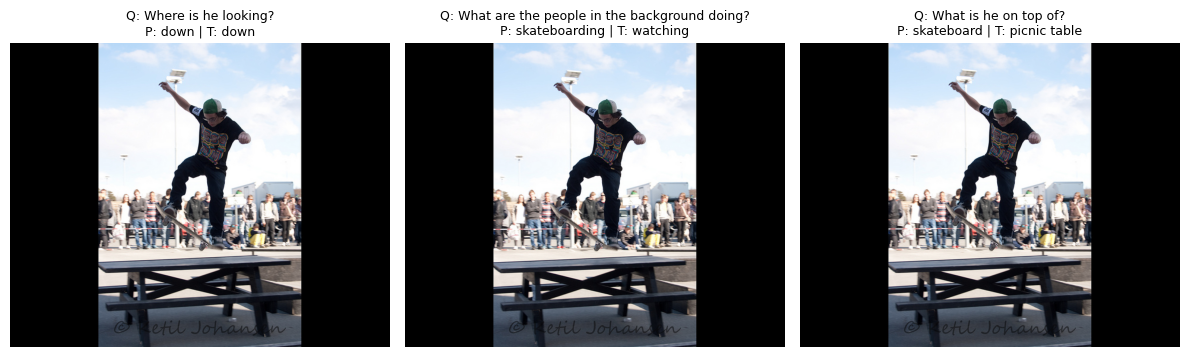

In [11]:
from torchmetrics import Accuracy
import matplotlib.pyplot as plt
import torchvision.transforms.functional as TF

import matplotlib.pyplot as plt
import torchvision.transforms.functional as TF
import torch

def evaluate_vqa(model, dataloader, dataset, id_to_answer, device, num_examples=5):
    model.eval()
    num_classes = len(id_to_answer)
    accuracy = Accuracy(task='multiclass', num_classes=num_classes).to(device)

    # ---- Top-1 accuracy ----
    with torch.no_grad():
        for image_feats, questions, answers in dataloader:
            image_feats = image_feats.to(device)
            questions = {k: v.to(device) for k, v in questions.items()}
            answers = answers.to(device)
            logits = model(image_feats, questions)
            preds = torch.argmax(logits, dim=1)
            accuracy.update(preds, answers)

    acc_val = accuracy.compute()
    print(f"Top-1 Accuracy: {acc_val*100:.2f}%")

    # ---- Qualitative examples ----
    print(f"\nShowing {num_examples} qualitative examples:")
    cols = min(num_examples, 5)
    rows = (num_examples + cols - 1) // cols
    plt.figure(figsize=(4 * cols, 4 * rows))

    for i in range(num_examples):
        q_data = dataset.questions[i]
        image_id = q_data['image_id']
        question_text = q_data['question']
        image_path = dataset._get_image_path(image_id)

        # Get prediction
        img_feat = dataset._get_image_feature(image_id).unsqueeze(0).to(device)
        q_enc = dataset.tokenizer(
            question_text,
            return_tensors='pt',
            padding='max_length',
            truncation=True,
            max_length=dataset.max_length
        )
        q_enc = {k: v.to(device) for k, v in q_enc.items()}

        with torch.no_grad():
            logits = model(img_feat, q_enc)
            pred_id = torch.argmax(logits, dim=1).item()
            pred_answer = id_to_answer.get(pred_id, "<unk>")

        true_answer = "<unk>"
        if dataset.annotations is not None:
            true_answer = dataset.annotations[i]['multiple_choice_answer']

        # ---- Plot in grid ----
        plt.subplot(rows, cols, i + 1)
        img = Image.open(image_path).convert('RGB')
        plt.imshow(img)
        plt.axis('off')
        plt.title(f"Q: {question_text}\nP: {pred_answer} | T: {true_answer}", fontsize=9)

    plt.tight_layout()
    plt.show()


val_dataset = VQAv2Dataset(
    image_dir='/content/drive/MyDrive/uni_datasets/VQAv2/images/val2014',
    questions_path='/content/drive/MyDrive/uni_datasets/VQAv2/questions/v2_OpenEnded_mscoco_val2014_questions.json',
    annotations_path='/content/drive/MyDrive/uni_datasets/VQAv2/annotations/v2_mscoco_val2014_annotations.json',
    tokenizer=tokenizer,
    device=device,
    answer_to_id=answer_to_id
)


val_subset = Subset(val_dataset, range(200))
val_loader = DataLoader(val_subset, batch_size=8, shuffle=False)
# evaluate_vqa(model, val_loader, val_dataset, id_to_answer, device, num_examples=5)
evaluate_vqa(CME_model, val_loader, val_dataset, id_to_answer, device, num_examples=3)


Top-1 Accuracy: 38.50%

Showing 3 qualitative examples:


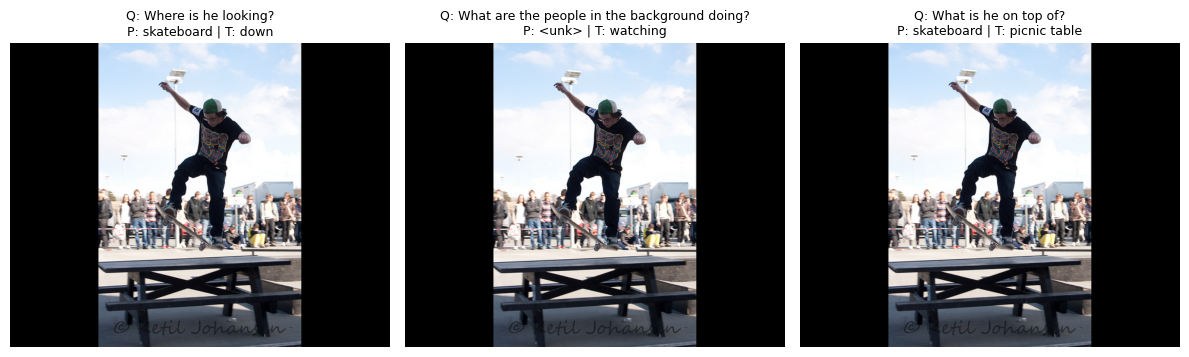

In [12]:
evaluate_vqa(concat_model, val_loader, val_dataset, id_to_answer, device, num_examples=3)

In [13]:
from transformers import CLIPProcessor, CLIPModel
import torch

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Load CLIP (zero-shot) model
clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

# Example zero-shot inference function
def zero_shot_vqa(images, questions, candidate_answers, processor, model, device):
    """
    images: list of PIL images
    questions: list of strings
    candidate_answers: list of strings (e.g., most common 1000 answers)
    """
    results = []
    for img, q in zip(images, questions):
        # Prepare CLIP inputs: text = question + candidate answer
        texts = [f"{q} {a}" for a in candidate_answers]

        inputs = processor(
            text=texts,
            images=img,
            return_tensors="pt",
            padding=True
        ).to(device)

        with torch.no_grad():
            outputs = model(**inputs)
            logits_per_image = outputs.logits_per_image  # shape [1, num_texts]
            pred_idx = logits_per_image.argmax().item()

        results.append(candidate_answers[pred_idx])
    return results

images = [Image.open(train_dataset._get_image_path(train_dataset.questions[i]['image_id'])).convert('RGB') for i in range(2)]
questions = [train_dataset.questions[i]['question'] for i in range(2)]
candidate_answers = list(answer_to_id.keys())[:1000]  # top 1000 answers


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]


Showing 10 zero-shot CLIP examples:


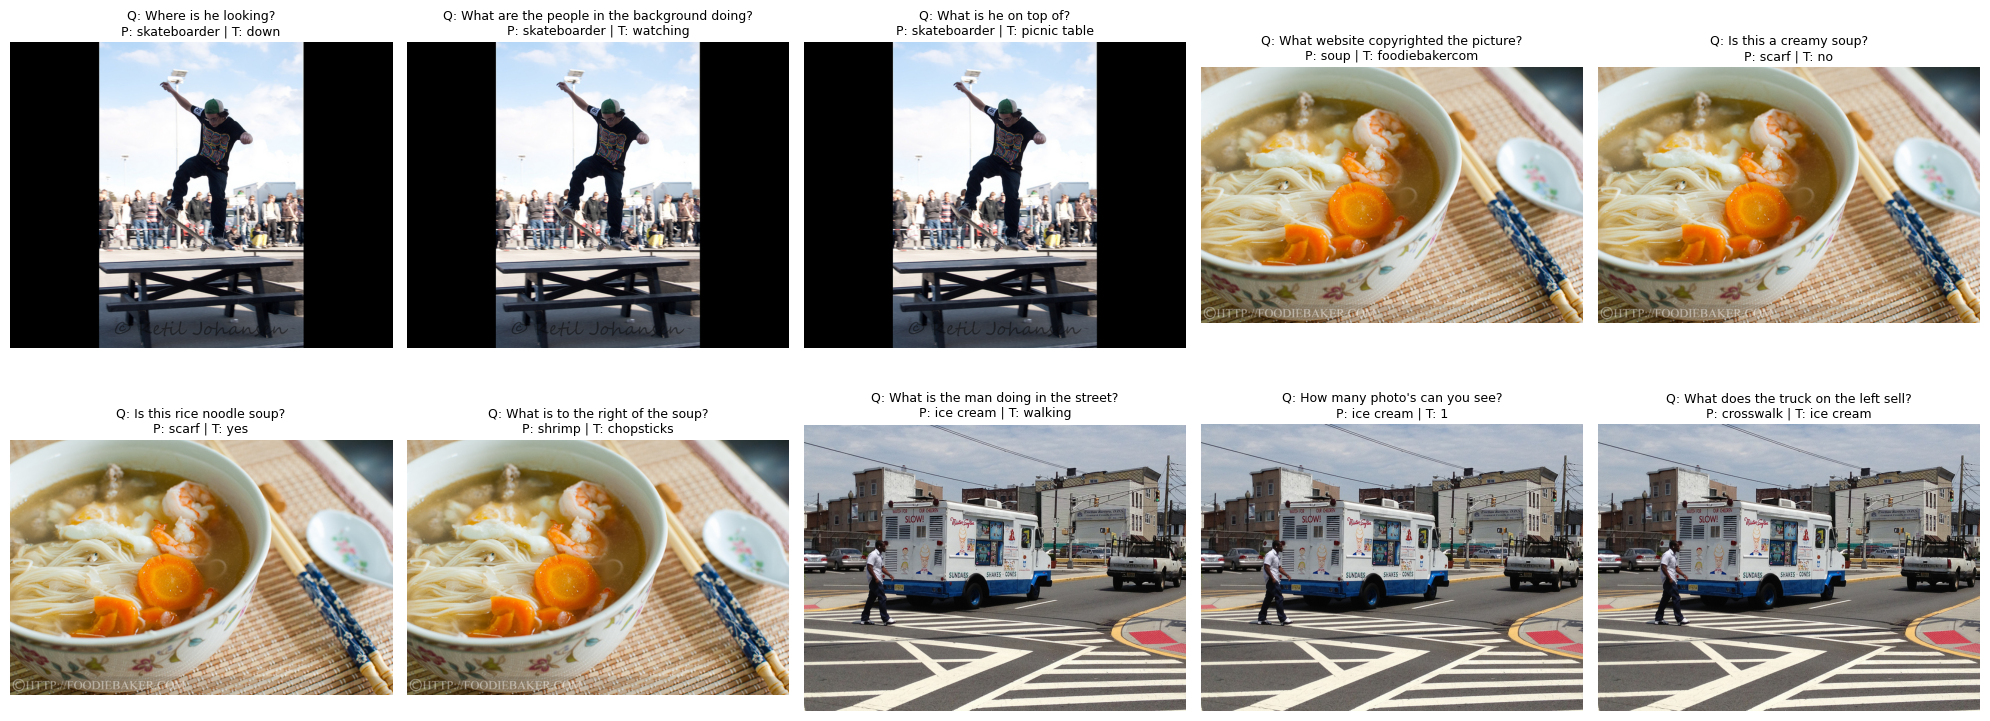

Zero-shot Top-1 Accuracy (sample of 10): 0.00%


In [14]:

def evaluate_vqa_clip(dataset, candidate_answers, processor, model, device, num_examples=5):
    """
    Zero-shot VQA evaluation using CLIP.
    """
    print(f"\nShowing {num_examples} zero-shot CLIP examples:")
    cols = min(num_examples, 5)
    rows = (num_examples + cols - 1) // cols
    plt.figure(figsize=(4 * cols, 4 * rows))

    correct = 0

    for i in range(num_examples):
        q_data = dataset.questions[i]
        image_id = q_data['image_id']
        question_text = q_data['question']
        image_path = dataset._get_image_path(image_id)

        img = Image.open(image_path).convert('RGB')
        texts = [f"{question_text} {a}" for a in candidate_answers]

        inputs = processor(
            text=texts,
            images=img,
            return_tensors="pt",
            padding=True
        ).to(device)

        with torch.no_grad():
            outputs = model(**inputs)
            logits_per_image = outputs.logits_per_image
            pred_idx = logits_per_image.argmax().item()
            pred_answer = candidate_answers[pred_idx]

        true_answer = "<unk>"
        if dataset.annotations is not None:
            true_answer = dataset.annotations[i]['multiple_choice_answer']
            if pred_answer == true_answer:
                correct += 1

        plt.subplot(rows, cols, i + 1)
        plt.imshow(img)
        plt.axis('off')
        plt.title(f"Q: {question_text}\nP: {pred_answer} | T: {true_answer}", fontsize=9)

    plt.tight_layout()
    plt.show()

    acc = correct / num_examples * 100
    print(f"Zero-shot Top-1 Accuracy (sample of {num_examples}): {acc:.2f}%")



evaluate_vqa_clip(
    dataset=val_dataset,
    candidate_answers=list(answer_to_id.keys())[:1000],
    processor=clip_processor,
    model=clip_model,
    device=device,
    num_examples=10
)